# Métricas e treinamento · Random Forest

GridSearchCV reproduzível, baseline e diagnósticos de **treino e validação**.
**TEST não é avaliado neste notebook.** Os gráficos leem artefatos persistidos;
abrir ou executar o notebook com a configuração padrão não repete a busca.

## 1. Protocolo e origem das métricas

- Alvo Machine failure; classe positiva 1. Cinco sensores e Type, sem IDs ou modos de falha.
- Mesma reserva da EDA: FIT 6.400, validação posterior 1.600 e TEST reservado 2.000.
- Três folds de prefixos crescentes em FIT. Sem shuffle ou gap; UDI não é data real.
- Critério: maior média de **AP entre candidatos com SMOTENC**. Desempate usa primeiro candidato.
- Elegíveis: SMOTENC e SMOTENC + pesos. Controles sem balanceamento e só pesos não podem vencer o refit.
- Imputação e padronização numérica, SMOTENC dentro dos treinos e one-hot depois da síntese.
- Todos os braços usam o mesmo pré-processamento; sampler desligado nos controles.
- A validação conserva seus registros e prevalência. Sem reamostragem na inferência.
- Refit somente em FIT de 6.400. Limiar fixo score >= 0,5; métricas de área usam predict_proba[:, 1].
- AP e AUPRC trapezoidal são métricas distintas. A CV do escolhido tem otimismo de seleção.
- Validação já usada no desenvolvimento; não é confirmação independente. TEST não é avaliado.

In [1]:
from pathlib import Path
import sys
import json
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'configs/training.json').is_file() and (p / 'pyproject.toml').is_file())
sys.path.insert(0, str(ROOT / 'src'))
from predictive_maintenance.training import run_experiment, latest_run
from predictive_maintenance.reporting import ModelReport
from predictive_maintenance.presentation import readable_table, readable_parameters, translate_text

def translated_markdown(text):
    return Markdown(translate_text(text))

from predictive_maintenance.data import sha256

MODEL_NAME = 'random_forest'
RUN_TRAINING = False  # True executa uma nova busca e preserva as anteriores.
RUN_ID = None  # Informe um ID salvo para revisar exatamente aquela execução.
if RUN_TRAINING:
    run = run_experiment(ROOT, MODEL_NAME)
elif RUN_ID:
    run = ROOT / 'reports/experiments' / RUN_ID
else:
    run = latest_run(ROOT, MODEL_NAME)
report = ModelReport(ROOT, run)
manifest = report.manifest
if manifest['model'] != MODEL_NAME:
    raise ValueError('Execução pertence a outro modelo.')
print('Execução:', manifest['run_id'])
print('Dataset SHA256:', manifest['dataset_sha256'])
print('CSV atual corresponde:', sha256(ROOT / manifest['data_config']['source']) == manifest['dataset_sha256'])
print('TEST avaliado:', manifest['test_evaluated'])
display(manifest['versions'])

Execução: train_random_forest_20261101T000049Z_f81b0b13
Dataset SHA256: dc6630cd9b1f0f853922fad78a1b6436570d3f1ec863f1dd5c4340ac56bc8a8e
CSV atual corresponde: True
TEST avaliado: False


{'scikit-learn': '1.9.1',
 'xgboost': '3.4.1',
 'pandas': '2.3.3',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'joblib': '1.6.0',
 'imbalanced-learn': '0.14.2'}

## 2. Grade condicional, custo e melhores parâmetros

72 candidatos × 3 folds = 216 ajustes de busca, mais 1 refit por modelo.
São 8 controles sem balanceamento, 16 só pesos, 16 SMOTENC e 32 SMOTENC + pesos.
Há ainda baseline e três diagnósticos por tamanho com parâmetros congelados.

300 árvores ficam **fixas** nesta rodada para concentrar orçamento no balanceamento.
A grade base tem 8 configurações. Pesos positivos 3 e 10, razões de síntese 0,25 e 0,5,
e k_neighbors=3 fixo (45 falhas no menor treino da CV).

`class_weight` dá peso maior à falha: XGBoost usa multiplicadores 3/10;
Random Forest usa dicionários {0: 1, 1: 3} / {0: 1, 1: 10}.
SMOTENC sozinho usa peso neutro. A combinação é comparada, sem presumir que vence.

`mean_test_*` significa validação dos folds em FIT, não o TEST reservado.
Grade condicional completa, incluindo controles e parâmetros, está no manifesto e abaixo.

Os quatro braços usam os mesmos hiperparâmetros base. Razões de síntese significam falhas/não falhas após a operação, não a fração da minoria no total. A padronização serve às distâncias do sampler. Pesos explícitos evitam o recálculo automático de balanced sobre dados já reamostrados. Critério Gini/bootstrap no RF e subsampling/regularização no XGBoost ficam fixos. Não há early stopping, undersampling ou ajuste de limiar.

**Grade condicional completa:**

Bloco 1

Parâmetro,Descrição,Valor
model__max_depth,Profundidade máxima,"[None, 10]"
model__min_samples_leaf,Observações mínimas por folha,"[1, 4]"
model__max_features,Variáveis por divisão,"['sqrt', 1.0]"
sampler,sampler,['passthrough']
model__class_weight,Peso das classes,[None]


Bloco 2

Parâmetro,Descrição,Valor
model__max_depth,Profundidade máxima,"[None, 10]"
model__min_samples_leaf,Observações mínimas por folha,"[1, 4]"
model__max_features,Variáveis por divisão,"['sqrt', 1.0]"
sampler,sampler,['passthrough']
model__class_weight,Peso das classes,"[{'0': 1, '1': 3}, {'0': 1, '1': 10}]"


Bloco 3

... (6 outputs left out)

**Melhores parâmetros na grade:**

Parâmetro,Descrição,Valor
model__class_weight,Peso das classes,None
model__max_depth,Profundidade máxima,None
model__max_features,Variáveis por divisão,1.0
model__min_samples_leaf,Observações mínimas por folha,4
sampler,sampler,SMOTENC
sampler__sampling_strategy,Razão de falhas/não falhas após SMOTENC,0.25


AP média de seleção: 0.4632
Tempo da busca: 277.8 s


,AP (score) — posição — validação CV,AP (score) — média — validação CV,AP (score) — desvio — validação CV,AP (score) — média — treino CV,AUPRC trapezoidal (score) — média — validação CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Tempo médio de ajuste (s),Parâmetros
4,1,"0,5069","0,0983","0,9992","0,5030","40,85%","41,93%","66,82%","2,0524","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
8,2,"0,4925","0,1137",1,"0,4915","39,71%","44,71%","55,67%","2,4406","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
6,3,"0,4905","0,1359","0,9990","0,4905","44,66%","48,58%","45,40%","4,4026","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
12,4,"0,4899","0,1111","0,9993","0,4852","40,42%","44,24%","61,80%","2,4620","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
0,5,"0,4880","0,1157",1,"0,4850","41,77%","42,97%","67,11%","2,2950","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
7,6,"0,4879","0,1293","0,9578","0,4880","40,60%","43,37%","59,37%","4,4337","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""sampler"": ""passthrough""}"
3,7,"0,4867","0,1302","0,9604","0,4872","40,60%","43,37%","59,37%","4,3503","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""sampler"": ""passthrough""}"
15,8,"0,4844","0,1529","0,9765","0,4859","38,53%","51,43%","48,12%","4,6576","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": 10, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""sampler"": ""passthrough""}"
1,9,"0,4842","0,0993","0,9568","0,4797","27,31%","27,20%","67,20%","2,1034","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 4, ""sampler"": ""passthrough""}"
11,10,"0,4809","0,1545","0,9786","0,4825","38,53%","51,43%","48,12%","4,7291","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": null, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""sampler"": ""passthrough""}"


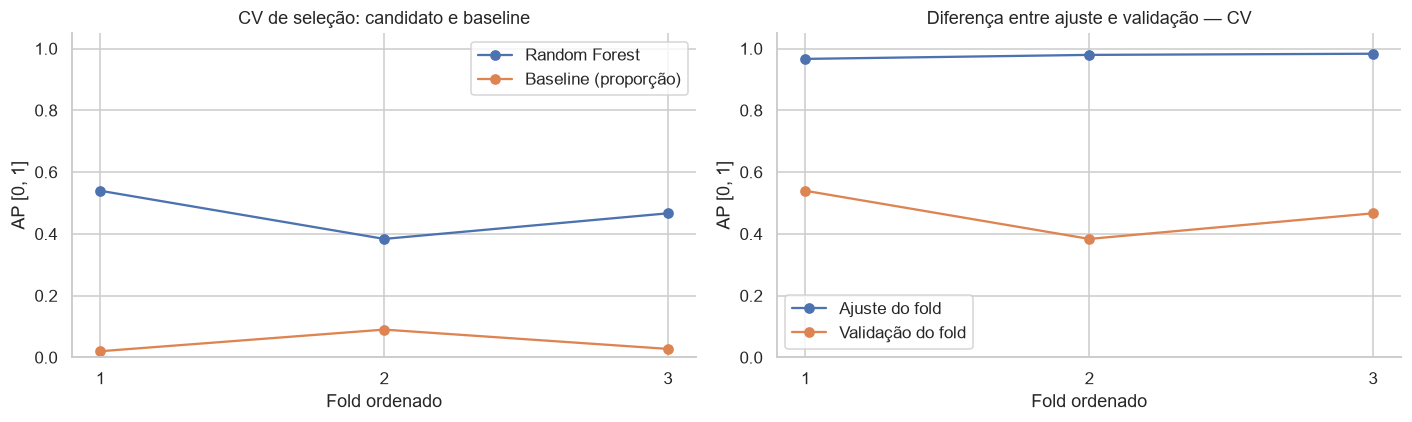

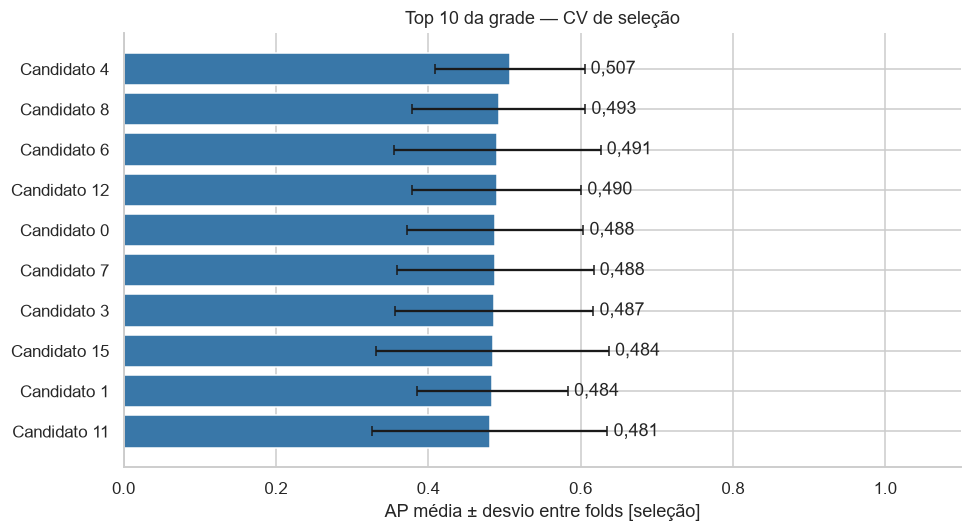

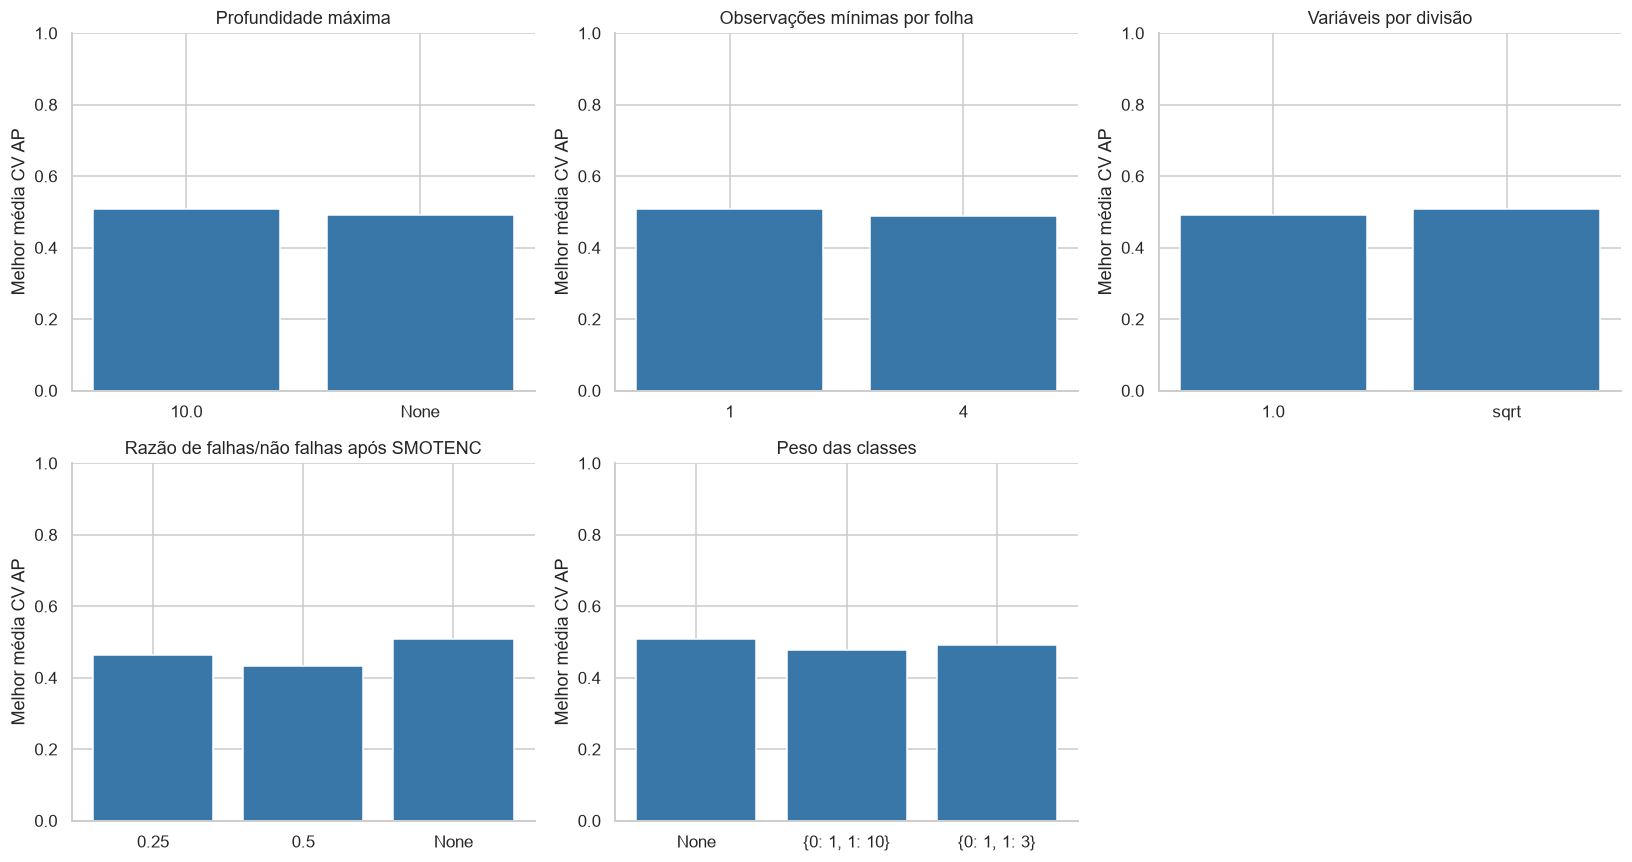

In [2]:
display(translated_markdown('**Grade condicional completa:**'))
for number, block in enumerate(manifest['search_grid'], start=1):
    display(translated_markdown(f'Bloco {number}'))
    display(readable_parameters(block))
print('Estratégia selecionada:', translate_text(manifest['balance_strategy']))
print('SMOTENC obrigatório no refit:', manifest['requires_smotenc'])
display(translated_markdown('**Parâmetros fixos:**'))
display(readable_parameters(manifest['fixed_params']))
display(translated_markdown('**Melhores parâmetros na grade:**'))
display(readable_parameters(manifest['best_params']))
print(f"AP média de seleção: {manifest['best_cv_ap']:.4f}")
print(f"Tempo da busca: {manifest['search_seconds']:.1f} s")
grid = report.table('grid_results')
selection_metric = manifest.get('selection_metric', 'ap')
columns = [f'rank_test_{selection_metric}', f'mean_test_{selection_metric}', f'std_test_{selection_metric}', f'mean_train_{selection_metric}', 'mean_test_ap', 'mean_test_auprc',
           'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'mean_fit_time', 'params']
display(readable_table(grid.sort_values(f'rank_test_{selection_metric}')[list(dict.fromkeys(columns))].head(10)))
report.cv_figures()

**Leitura dos perfis:** cada barra mostra o melhor AP médio entre combinações
daquele valor, mantendo os demais parâmetros livres na grade. Não é efeito
isolado de hiperparâmetro. Os desvios do top 10 são dispersão entre folds,
não intervalos de confiança ou evidência de superioridade estatística.

## 3. Estatísticas por fold e baseline

`CV_SELECTION` refere-se ao candidato escolhido nas mesmas amostras usadas na
seleção, sem CV aninhada. Não são predições OOF nem resultado de teste.
O baseline Dummy usa a proporção observada no treino de cada fold.
Precision sem alertas é 0 no scorer da CV; nos diagnósticos de segmentos é indefinida (NaN).

In [3]:
folds = report.table('fold_metrics')
display(readable_table(folds))
display(readable_table(report.summary()))
selected_folds = folds.loc[folds.model.eq(MODEL_NAME)]
display(translated_markdown(f"**AP de seleção:** {selected_folds.validation_ap.mean():.3f} ± "
                f"{selected_folds.validation_ap.std(ddof=1):.3f} (desvio amostral entre folds). "
                'Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.'))

,Receita,Fold ordenado,Origem,Observações de treino,Observações de validação,Falhas no treino,Falhas na validação,Limiar de alerta,AP (score) — treino,AP (score) — validação,ROC-AUC (score) — treino,ROC-AUC (score) — validação,F1 (%) — treino,F1 (%) — validação,Recall (%) — treino,Recall (%) — validação,Precision (%) — treino,Precision (%) — validação,Acurácia balanceada (%) — treino,Acurácia balanceada (%) — validação,AUPRC trapezoidal (score) — treino,AUPRC trapezoidal (score) — validação
0,Random Forest,1,CV de seleção,1.600,1.600,45,32,"0,5000","0,9665","0,5395","0,9987","0,9052","86,02%","48,35%","88,89%","68,75%","83,33%","37,29%","94,19%","83,20%","0,9662","0,5356"
1,Baseline (proporção),1,CV do baseline,1.600,1.600,45,32,"0,5000","0,0281","0,0200","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5141","0,5100"
2,Random Forest,2,CV de seleção,3.200,1.600,77,144,"0,5000","0,9795","0,3836","0,9994","0,7598","91,14%","33,67%","93,51%","22,92%","88,89%","63,46%","96,61%","60,81%","0,9794","0,3857"
3,Baseline (proporção),2,CV do baseline,3.200,1.600,77,144,"0,5000","0,0241","0,0900","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5120","0,5450"
4,Random Forest,3,CV de seleção,4.800,1.600,221,44,"0,5000","0,9832","0,4665","0,9990","0,9319","92,31%","36,46%","92,31%","75,00%","92,31%","24,09%","95,97%","84,16%","0,9832","0,4653"
5,Baseline (proporção),3,CV do baseline,4.800,1.600,221,44,"0,5000","0,0460","0,0275","0,5000","0,5000","0,00%","0,00%","0,00%","0,00%","0,00%","0,00%","50,00%","50,00%","0,5230","0,5138"


**AP de seleção:** 0,463 ± 0,078 (desvio amostral entre folds). Deslocamentos entre blocos e baixo suporte positivo limitam a interpretação.

## 4. FIT reajustado versus VALIDAÇÃO

`FIT_RESUBSTITUTION` é desempenho sobre o próprio ajuste, sujeito a sobreajuste.
`VALIDATION_TRAIN_BLOCK` é o bloco posterior fora da busca. Mesmos dados e limiar
para o candidato e o baseline. Nas tabelas e barras, F1/Recall/Precision e taxas aparecem em %, com vírgula decimal; AP e ROC-AUC permanecem scores em 0–1. Desvios de percentuais são pontos percentuais (p.p.). Os artefatos numéricos não são alterados.
`Não definido` nas barras indica ausência de alertas; a altura 0 é apenas convenção visual.

,Receita,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Random Forest,Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.111,24,18,247,"92,16%","93,21%","91,14%","99,61%","99,71%","0,39%","6,79%","4,23%","99,34%","96,41%","0,9859","0,9859","0,9993","0,0064","0,0280","0,9183","0,9182"
1,Random Forest,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.553,12,10,25,"69,44%","71,43%","67,57%","99,23%","99,36%","0,77%","28,57%","2,31%","98,62%","85,33%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6877","0,6874"
2,Baseline (proporção),Treino (reavaliação no ajuste),6.400,265,"4,14%","0,5000",6.135,0,265,0,"0,00%","0,00%",Não definido,"100,00%","95,86%","0,00%","100,00%","0,00%","95,86%","50,00%","0,0414","0,5207","0,5000","0,0397","0,1724",0,0
3,Baseline (proporção),Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.565,0,35,0,"0,00%","0,00%",Não definido,"100,00%","97,81%","0,00%","100,00%","0,00%","97,81%","50,00%","0,0219","0,5109","0,5000","0,0218","0,1110",0,0


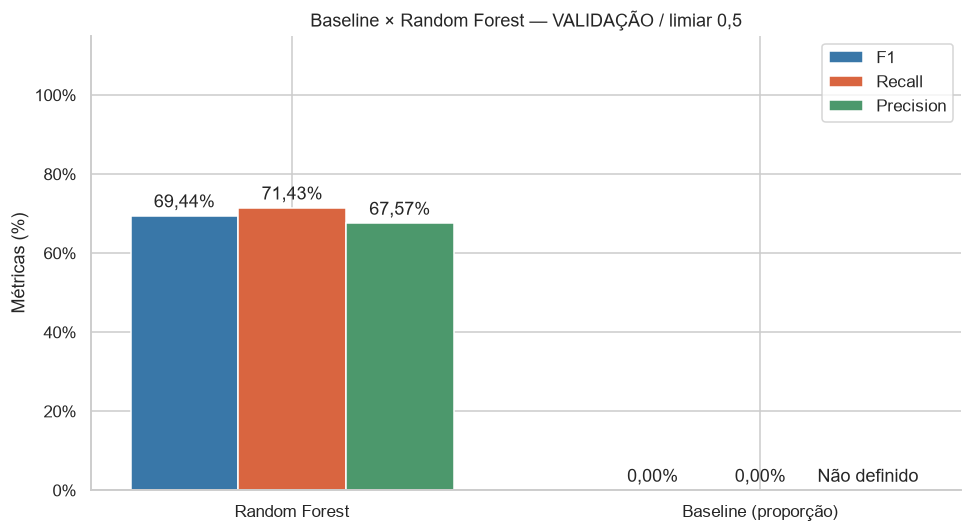

**Validação:** AUPRC=0,748; AP=0,750; F1=69,44%; Recall=71,43%; Precision=67,57%. Diferença de AP entre ajuste e validação = 0,236. São 35 falhas em 1600 observações. A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.

In [4]:
metrics = report.table('model_metrics')
display(readable_table(metrics))
report.comparison()
validation = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('VALIDATION_TRAIN_BLOCK')].iloc[0]
fit = metrics.loc[metrics.model.eq(MODEL_NAME) & metrics.origin.eq('FIT_RESUBSTITUTION')].iloc[0]
display(translated_markdown(f"**Validação:** AUPRC={validation.auprc:.3f}; AP={validation.ap:.3f}; F1={validation.f1:.2%}; "
    f"Recall={validation.recall:.2%}; Precision={validation.precision:.2%}. "
    f"Diferença de AP entre ajuste e validação = {fit.ap - validation.ap:.3f}. "
    f"São {int(validation.positives)} falhas em {int(validation.n)} observações. "
    'A diferença pode refletir sobreajuste e mudança entre blocos; não prova causalidade.'))

## 5. Matriz de confusão e relatório por classe

Eixo vertical real, horizontal previsto; classe positiva = falha. Matrizes em
contagens e normalizadas pela classe real. `zero_division=0` no relatório por classe.

,Classe / média,Precision (%),Recall (%),F1 (%),Observações da classe
0,Sem falha (0),"99,36%","99,23%","99,30%",1.565
1,Falha (1),"67,57%","71,43%","69,44%",35
2,Acurácia,"98,62%","98,62%","98,62%","0,9862"
3,Média macro,"83,46%","85,33%","84,37%",1.600
4,Média ponderada,"98,66%","98,62%","98,64%",1.600


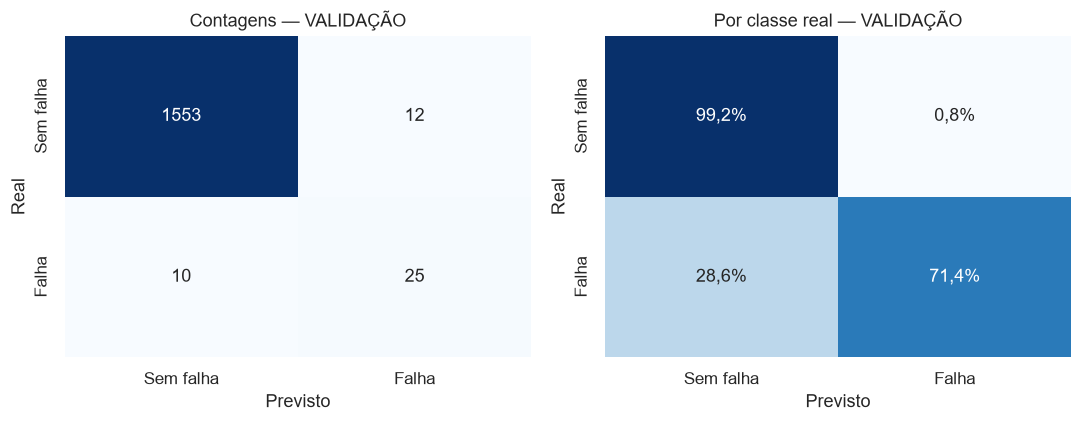

**Carga de revisão no bloco:** 37 alertas; 12 falsos positivos e 10 falhas perdidas. Custos e capacidade operacional ainda não foram informados.

In [5]:
display(readable_table(report.table('classification_report')))
report.confusion()
display(translated_markdown(f"**Carga de revisão no bloco:** {int(validation.tp + validation.fp)} alertas; "
                f"{int(validation.fp)} falsos positivos e {int(validation.fn)} falhas perdidas. "
                'Custos e capacidade operacional ainda não foram informados.'))

## 6. PR, ROC, confiabilidade e distribuição dos scores

AP e ROC usam scores positivos. A prevalência é a referência da PR. ROC complementa
a análise de classe rara. A curva de confiabilidade usa até 10 grupos por quantis;
não ajusta calibrador e não comprova calibração. Pesos de classe podem alterar os scores.

**Nota sobre AUPRC:** uma pontuação constante pode gerar poucos pontos na curva PR; a interpolação trapezoidal pode resultar em área alta mesmo com AP igual à prevalência. Por isso AP e AUPRC são mostradas separadamente, inclusive no baseline.

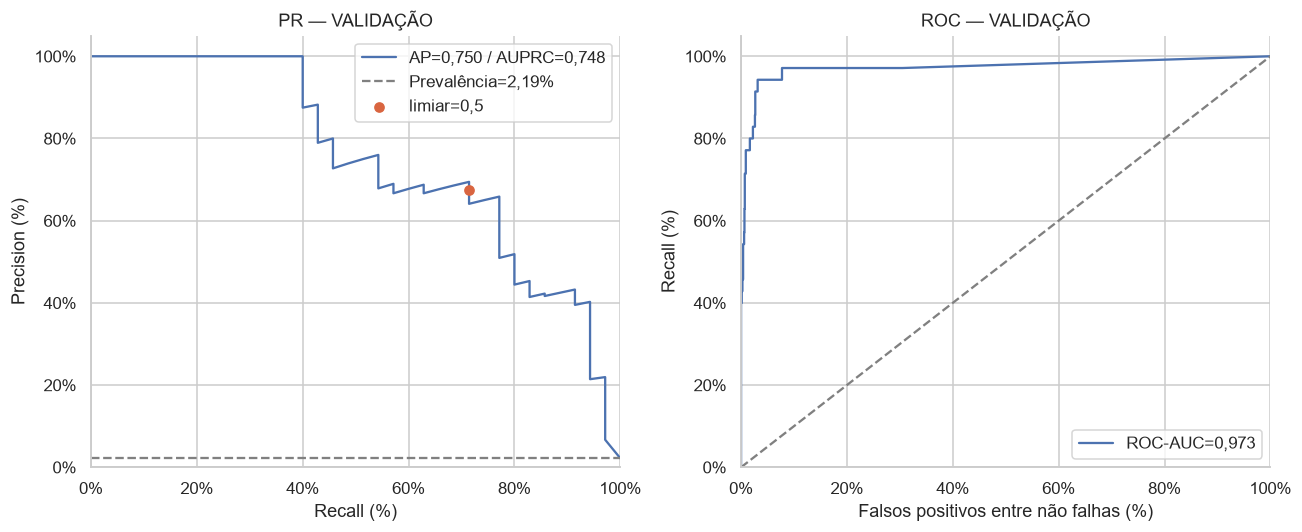

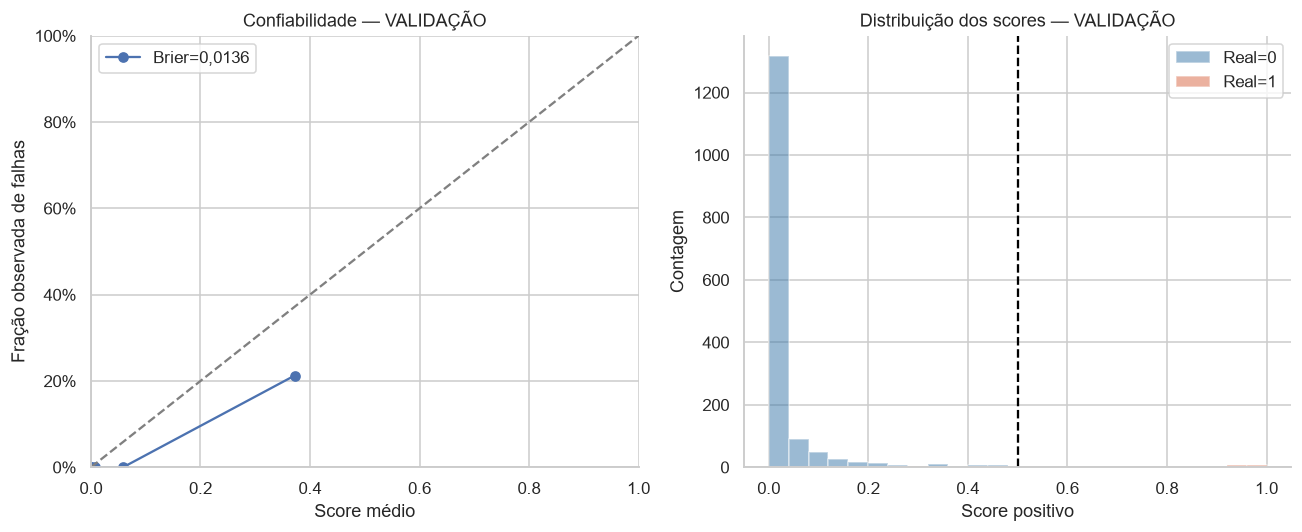

,Score médio,Taxa observada de falhas (%)
0,0,"0,09%"
1,"0,0006","0,00%"
2,"0,0076","0,00%"
3,"0,0586","0,00%"
4,"0,3720","21,25%"


**Diagnóstico probabilístico:** Brier=0,0136; Log Loss=0,0707. Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.

In [6]:
report.probability_figures()
display(readable_table(report.table('calibration')))
display(translated_markdown(f"**Diagnóstico probabilístico:** Brier={validation.brier:.4f}; "
                f"Log Loss={validation.log_loss:.4f}. "
                'Amostra com poucas falhas limita a estabilidade da curva de confiabilidade.'))

## 7. Sensibilidade ao threshold — sem tuning

O destaque mostra a referência 0,5. Varrer limiares na validação é **diagnóstico**,
sem mudar o pacote ou declarar um ótimo. Recall/Precision/F1 mudam; AP dos mesmos
scores não muda. Uma escolha operacional futura exige objetivo e validação própria.

,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Validação (somente diagnóstico),1.600,35,"2,19%","0,0500",1.342,223,1,34,"23,29%","97,14%","13,23%","85,75%","99,93%","14,25%","2,86%","16,06%","86,00%","91,45%","0,7499","0,7479","0,9728","0,0136","0,0707","0,3302","0,2022"
1,Validação (somente diagnóstico),1.600,35,"2,19%","0,1000",1.432,133,1,34,"33,66%","97,14%","20,36%","91,50%","99,93%","8,50%","2,86%","10,44%","91,62%","94,32%","0,7499","0,7479","0,9728","0,0136","0,0707","0,4241","0,3117"
2,Validação (somente diagnóstico),1.600,35,"2,19%","0,2000",1.498,67,2,33,"48,89%","94,29%","33,00%","95,72%","99,87%","4,28%","5,71%","6,25%","95,69%","95,00%","0,7499","0,7479","0,9728","0,0136","0,0707","0,5439","0,4718"
3,Validação (somente diagnóstico),1.600,35,"2,19%","0,3000",1.523,42,3,32,"58,72%","91,43%","43,24%","97,32%","99,80%","2,68%","8,57%","4,62%","97,19%","94,37%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6181","0,5745"
4,Validação (somente diagnóstico),1.600,35,"2,19%","0,4000",1.538,27,7,28,"62,22%","80,00%","50,91%","98,27%","99,55%","1,73%","20,00%","3,44%","97,88%","89,14%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6284","0,6118"
5,Validação (somente diagnóstico),1.600,35,"2,19%","0,5000",1.553,12,10,25,"69,44%","71,43%","67,57%","99,23%","99,36%","0,77%","28,57%","2,31%","98,62%","85,33%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6877","0,6874"
6,Validação (somente diagnóstico),1.600,35,"2,19%","0,6000",1.555,10,14,21,"63,64%","60,00%","67,74%","99,36%","99,11%","0,64%","40,00%","1,94%","98,50%","79,68%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6299","0,6287"
7,Validação (somente diagnóstico),1.600,35,"2,19%","0,7000",1.559,6,17,18,"61,02%","51,43%","75,00%","99,62%","98,92%","0,38%","48,57%","1,50%","98,56%","75,52%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6143","0,6031"
8,Validação (somente diagnóstico),1.600,35,"2,19%","0,8000",1.559,6,19,16,"56,14%","45,71%","72,73%","99,62%","98,80%","0,38%","54,29%","1,38%","98,44%","72,67%","0,7499","0,7479","0,9728","0,0136","0,0707","0,5694","0,5539"
9,Validação (somente diagnóstico),1.600,35,"2,19%","0,9000",1.561,4,20,15,"55,56%","42,86%","78,95%","99,74%","98,73%","0,26%","57,14%","1,19%","98,50%","71,30%","0,7499","0,7479","0,9728","0,0136","0,0707","0,5753","0,5486"


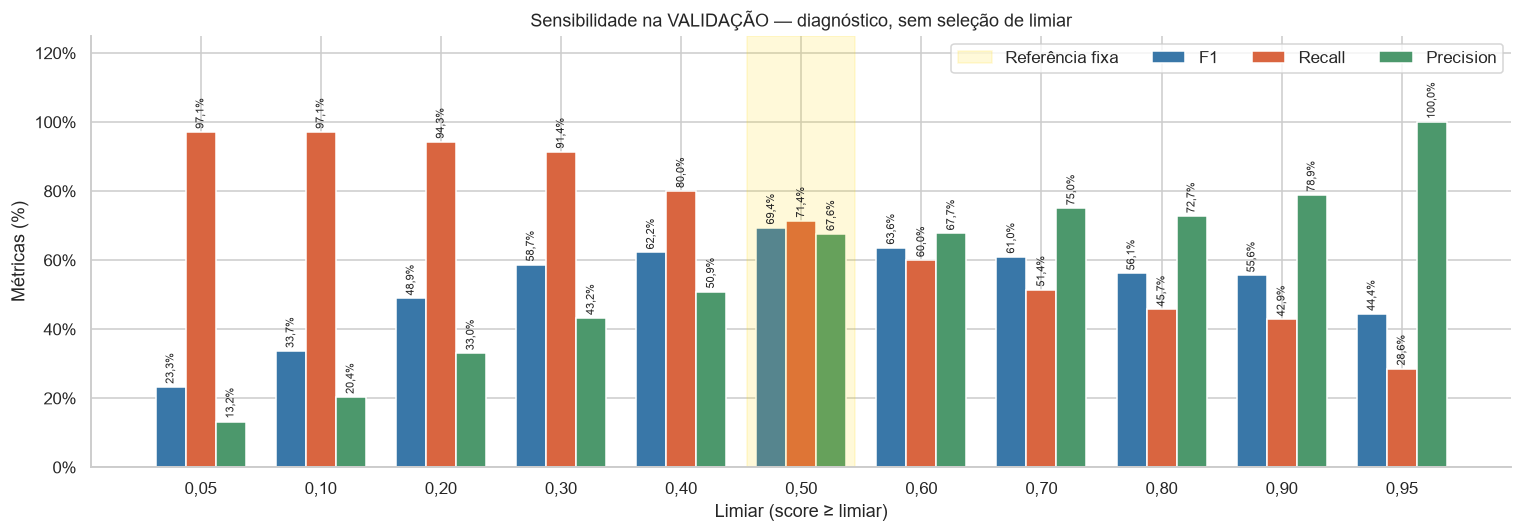

In [7]:
display(readable_table(report.table('threshold_diagnostics')))
report.threshold_figure()

## 8. Associação versus importância preditiva

Associação calculada em FIT: Spearman para sensores, Cramér V para Type (magnitude
com medidas distintas, não equivalentes). Importância por permutação no bloco de
validação, agregada por entrada original passando pelo pipeline completo.
A unidade é queda de AP; as barras de erro são desvio das permutações, não confiança.
Correlação entre sensores pode repartir importâncias. Nada foi removido com esse diagnóstico.

,Variável,Pearson com falha — treino,Spearman com falha — treino,Magnitude da associação — treino,Medida de associação,Queda de AP por permutação — validação,Queda de AUPRC por permutação — validação,Desvio da permutação de AUPRC (score),Desvio da permutação (score)
0,Temperatura do ar [K],"0,0861","0,0897","0,0897",Módulo de Spearman,"0,0525","0,0542","0,0267","0,0252"
1,Temperatura do processo [K],"0,0439","0,0500","0,0500",Módulo de Spearman,"0,0308","0,0319","0,0251","0,0242"
2,Velocidade de rotação [rpm],"-0,0580","-0,1982","0,1982",Módulo de Spearman,"0,2196","0,2236","0,0578","0,0547"
3,Torque [Nm],"0,2110","0,1950","0,1950",Módulo de Spearman,"0,6914","0,6929","0,0072","0,0099"
4,Desgaste da ferramenta [min],"0,0925","0,0885","0,0885",Módulo de Spearman,"0,3660","0,3649","0,0466","0,0469"
5,Tipo,Não definido,Não definido,"0,0318",V de Cramér,"0,0557","0,0570","0,0223","0,0217"


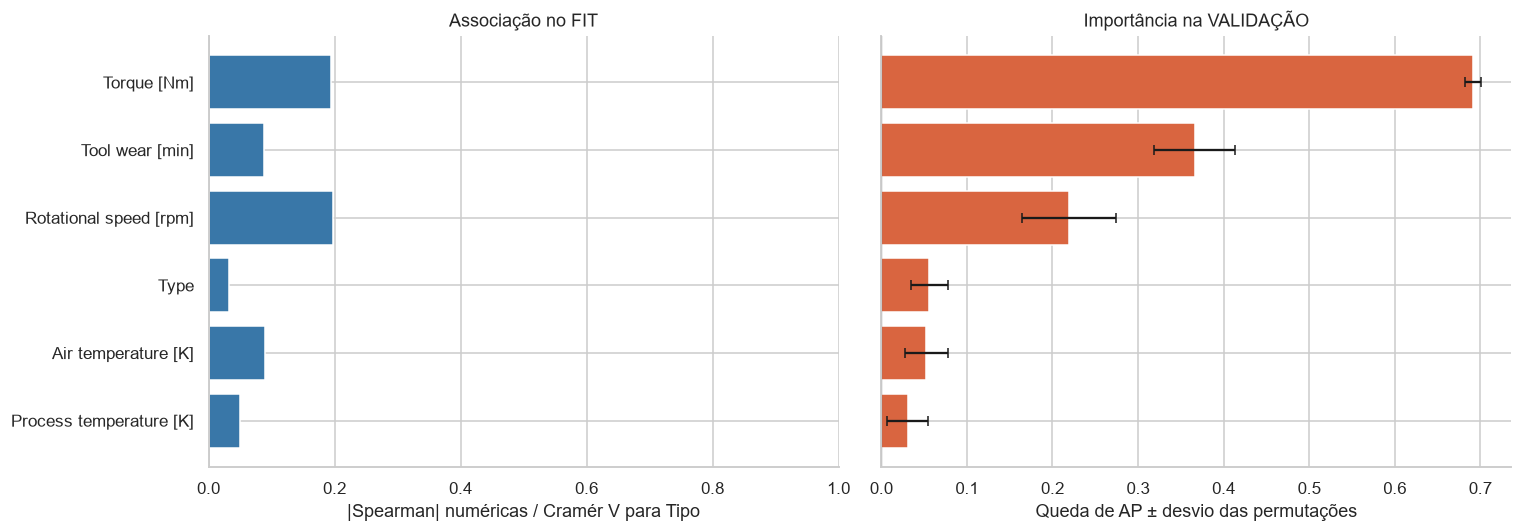

In [8]:
display(readable_table(report.table('feature_association_importance')))
report.feature_figure()

## 9. Diagnóstico por tamanho do prefixo

Parâmetros congelados da busca, prefixos ordenados e a mesma validação. Prefixos
de tamanhos distintos abrangem regimes diferentes: **não é uma learning curve i.i.d.
controlada**. É diagnóstico descritivo; não escolhe novamente os parâmetros.

,Observações de treino,Origem,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,1.600,Treino (prefixo),1.600,45,"2,81%","0,5000",1.547,8,5,40,"86,02%","88,89%","83,33%","99,49%","99,68%","0,51%","11,11%","3,00%","99,19%","94,19%","0,9665","0,9662","0,9987","0,0055","0,0216","0,8565","0,8560"
1,1.600,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.526,39,6,29,"56,31%","82,86%","42,65%","97,51%","99,61%","2,49%","17,14%","4,25%","97,19%","90,18%","0,5499","0,5387","0,9511","0,0205","0,0965","0,5827","0,5501"
2,3.200,Treino (prefixo),3.200,77,"2,41%","0,5000",3.114,9,5,72,"91,14%","93,51%","88,89%","99,71%","99,84%","0,29%","6,49%","2,53%","99,56%","96,61%","0,9795","0,9794","0,9994","0,0054","0,0241","0,9095","0,9092"
3,3.200,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.540,25,7,28,"63,64%","80,00%","52,83%","98,40%","99,55%","1,60%","20,00%","3,31%","98,00%","89,20%","0,7198","0,7175","0,9511","0,0171","0,0870","0,6408","0,6265"
4,4.800,Treino (prefixo),4.800,221,"4,60%","0,5000",4.562,17,17,204,"92,31%","92,31%","92,31%","99,63%","99,63%","0,37%","7,69%","4,60%","99,29%","95,97%","0,9832","0,9832","0,9990","0,0072","0,0315","0,9194","0,9194"
5,4.800,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.547,18,12,23,"60,53%","65,71%","56,10%","98,85%","99,23%","1,15%","34,29%","2,56%","98,12%","82,28%","0,7027","0,6999","0,9671","0,0166","0,0843","0,5977","0,5957"
6,6.400,Treino (prefixo),6.400,265,"4,14%","0,5000",6.111,24,18,247,"92,16%","93,21%","91,14%","99,61%","99,71%","0,39%","6,79%","4,23%","99,34%","96,41%","0,9859","0,9859","0,9993","0,0064","0,0280","0,9183","0,9182"
7,6.400,Validação (bloco de TRAIN),1.600,35,"2,19%","0,5000",1.553,12,10,25,"69,44%","71,43%","67,57%","99,23%","99,36%","0,77%","28,57%","2,31%","98,62%","85,33%","0,7499","0,7479","0,9728","0,0136","0,0707","0,6877","0,6874"


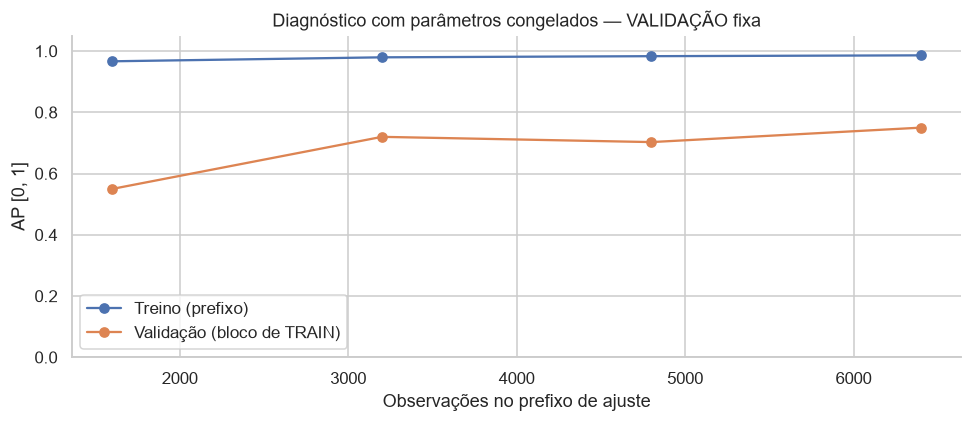

In [9]:
display(readable_table(report.table('learning_diagnostic')))
report.learning_figure()

## 10. Erros por segmento e ordem dos registros

Contagens, taxas reais, TP/FP/FN/TN e métricas por Type e faixas de sensores.
Limites das faixas aprendidos apenas em FIT; extremos cobrem valores futuros.
NaN indica denominador inexistente. Não somar suportes de features diferentes:
as mesmas observações aparecem em cada análise. UDI não representa tempo decorrido.

,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Tipo,H,147,1,"0,68%","0,5000",146,0,0,1,"100,00%","100,00%","100,00%","100,00%","100,00%","0,00%","0,00%","0,68%","100,00%","100,00%",1,1,1,"0,0072","0,0328",1,1
1,Tipo,L,968,24,"2,48%","0,5000",936,8,7,17,"69,39%","70,83%","68,00%","99,15%","99,26%","0,85%","29,17%","2,58%","98,45%","84,99%","0,7736","0,7718","0,9643","0,0146","0,0862","0,6861","0,6859"
2,Tipo,M,485,10,"2,06%","0,5000",471,4,3,7,"66,67%","70,00%","63,64%","99,16%","99,37%","0,84%","30,00%","2,27%","98,56%","84,58%","0,7220","0,7055","0,9918","0,0135","0,0513","0,6601","0,6593"


,Variável de agrupamento,Faixa / categoria,Observações,Falhas confirmadas,Prevalência de falhas (%),Limiar de alerta,TN: não falhas liberadas,FP: falsos alertas,FN: falhas não detectadas,TP: falhas detectadas,F1 (%),Recall (%),Precision (%),Especificidade (%),Valor preditivo negativo (%),Falsos positivos entre não falhas (%),Falhas não detectadas (%),Taxa de alertas (%),Acurácia (%),Acurácia balanceada (%),AP (score),AUPRC trapezoidal (score),ROC-AUC (score),Brier score,Log Loss,MCC,Kappa
0,Temperatura do ar [K],"(298.1, 299.6]",33,0,"0,00%","0,5000",33,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0038","0,0168",Não definido,Não definido
1,Temperatura do ar [K],"(299.6, 301.3]",1.359,30,"2,21%","0,5000",1.318,11,8,22,"69,84%","73,33%","66,67%","99,17%","99,40%","0,83%","26,67%","2,43%","98,60%","86,25%","0,7635","0,7617","0,9703","0,0136","0,0734","0,6921","0,6913"
2,Temperatura do ar [K],"(301.3, 302.4]",208,5,"2,40%","0,5000",202,1,2,3,"66,67%","60,00%","75,00%","99,51%","99,02%","0,49%","40,00%","1,92%","98,56%","79,75%","0,7933","0,7747","0,9911","0,0149","0,0618","0,6637","0,6594"
3,Temperatura do processo [K],"(309.4, 310.5]",521,9,"1,73%","0,5000",506,6,2,7,"63,64%","77,78%","53,85%","98,83%","99,61%","1,17%","22,22%","2,50%","98,46%","88,30%","0,7258","0,7226","0,9193","0,0157","0,1182","0,6399","0,6288"
4,Temperatura do processo [K],"(310.5, 311.3]",544,12,"2,21%","0,5000",530,2,2,10,"83,33%","83,33%","83,33%","99,62%","99,62%","0,38%","16,67%","2,21%","99,26%","91,48%","0,9107","0,9077","0,9967","0,0100","0,0418","0,8296","0,8296"
5,Temperatura do processo [K],"(311.3, inf]",535,14,"2,62%","0,5000",517,4,6,8,"61,54%","57,14%","66,67%","99,23%","98,85%","0,77%","42,86%","2,24%","98,13%","78,19%","0,7283","0,7198","0,9894","0,0151","0,0539","0,6078","0,6059"
6,Velocidade de rotação [rpm],"(-inf, 1406.0]",334,21,"6,29%","0,5000",305,8,3,18,"76,60%","85,71%","69,23%","97,44%","99,03%","2,56%","14,29%","7,78%","96,71%","91,58%","0,8287","0,8249","0,9855","0,0341","0,1173","0,7534","0,7485"
7,Velocidade de rotação [rpm],"(1406.0, 1469.0]",293,4,"1,37%","0,5000",287,2,2,2,"50,00%","50,00%","50,00%","99,31%","99,31%","0,69%","50,00%","1,37%","98,63%","74,65%","0,5563","0,5195","0,9836","0,0148","0,0634","0,4931","0,4931"
8,Velocidade de rotação [rpm],"(1469.0, 1542.0]",364,1,"0,27%","0,5000",363,0,1,0,"0,00%","0,00%",Não definido,"100,00%","99,73%","0,00%","100,00%","0,00%","99,73%","50,00%",1,1,1,"0,0018","0,0087",0,0
9,Velocidade de rotação [rpm],"(1542.0, 1643.0]",281,0,"0,00%","0,5000",281,0,0,0,"0,00%",Não definido,Não definido,"100,00%","100,00%","0,00%",Não definido,"0,00%","100,00%",Não definido,Não definido,Não definido,Não definido,"0,0026","0,0122",Não definido,Não definido


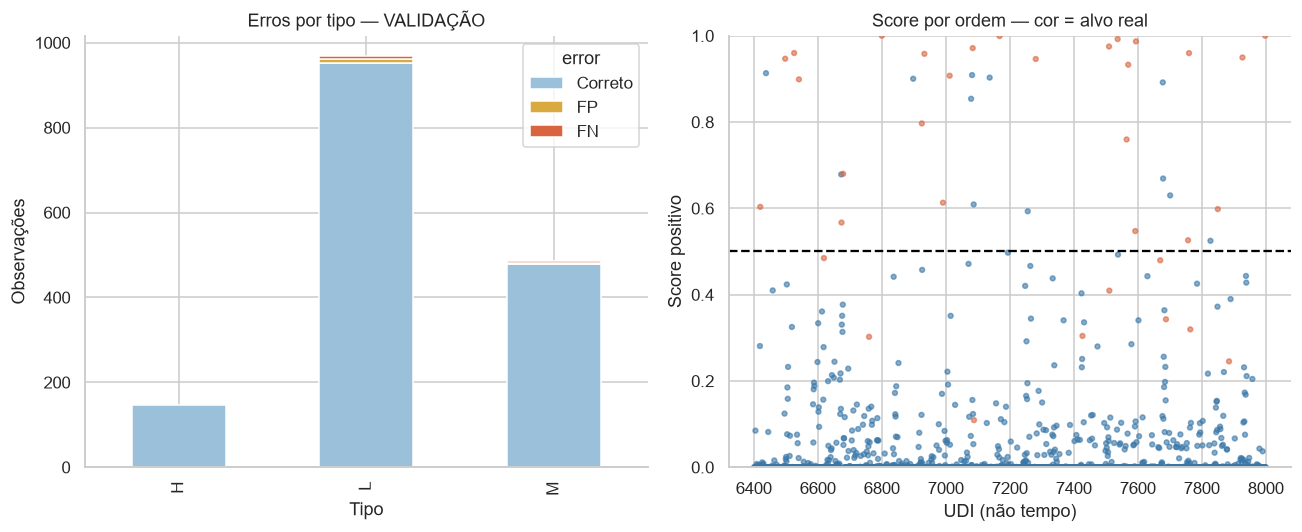

In [10]:
display(readable_table(report.table('segment_type')))
display(readable_table(report.table('segment_numeric')))
report.error_figure()

## 11. Artefato, reprodutibilidade e limites

O pipeline local corresponde ao refit em FIT (6.400), não a um modelo reajustado
nas 8.000 observações ou selecionado como vencedor do projeto. Não existe avaliação TEST.
O binário é local e ignorado no Git; carregar somente artefatos de origem confiável.

In [11]:
print('Pipeline:', manifest['model_path'])
print('SHA256:', manifest['model_sha256'])
print('Equivalência após serialização:', manifest['serialization_verified'])
print('Política de limiar:', manifest['threshold_policy'])
print('Figuras:', report.figures.relative_to(ROOT))
print('Tabelas:', report.tables.relative_to(ROOT))
display(manifest['limitations'])
display(translated_markdown('**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, '
    'considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. '
    'Não ajustar features ou threshold com TEST. Nenhum vencedor de produção foi declarado.'))

Pipeline: models/train_random_forest_20261101T000049Z_f81b0b13/pipeline.joblib
SHA256: 8765b8dbf0b82ed050d799f8195e5947c33ed44ce5dc7a6d95edf59a370831ac
Equivalência após serialização: True
Política de limiar: fixed reference; not tuned
Figuras: reports\figures\train_random_forest_20261101T000049Z_f81b0b13
Tabelas: reports\metrics\train_random_forest_20261101T000049Z_f81b0b13


['UDI is record order, not verified time',
 'no gap or physical machine ID',
 'CV winner scores are selection-optimistic',
 'validation belongs to EDA-explored TRAIN',
 'probability calibration not demonstrated',
 'no final TEST evaluation']

**Próxima decisão:** comparar os dois candidatos sob este mesmo protocolo, considerando AP, falhas perdidas, falsos alarmes, estabilidade e custo. Não ajustar features ou limiar com TEST. Nenhum vencedor de produção foi declarado.

## 12. Comparação com a execução anterior

Mesmos registros e folds. AUPRC trapezoidal e AP são calculadas com predict_proba[:, 1]; a execução anterior já usava predict_proba. Comparação na validação de desenvolvimento reutilizada; não demonstra generalização independente. O efeito conjunto de sampler, pesos e critério de busca não pode ser atribuído somente ao SMOTENC. TEST permanece reservado.

,Versão,Limiar de alerta,AUPRC trapezoidal (score),AP (score),F1 (%),Recall (%),Precision (%),FP: falsos alertas,FN: falhas não detectadas
0,Anterior,"0,5000","0,7180","0,7205","56,60%","42,86%","83,33%",3,20
1,Atual,"0,5000","0,7479","0,7499","69,44%","71,43%","67,57%",12,10


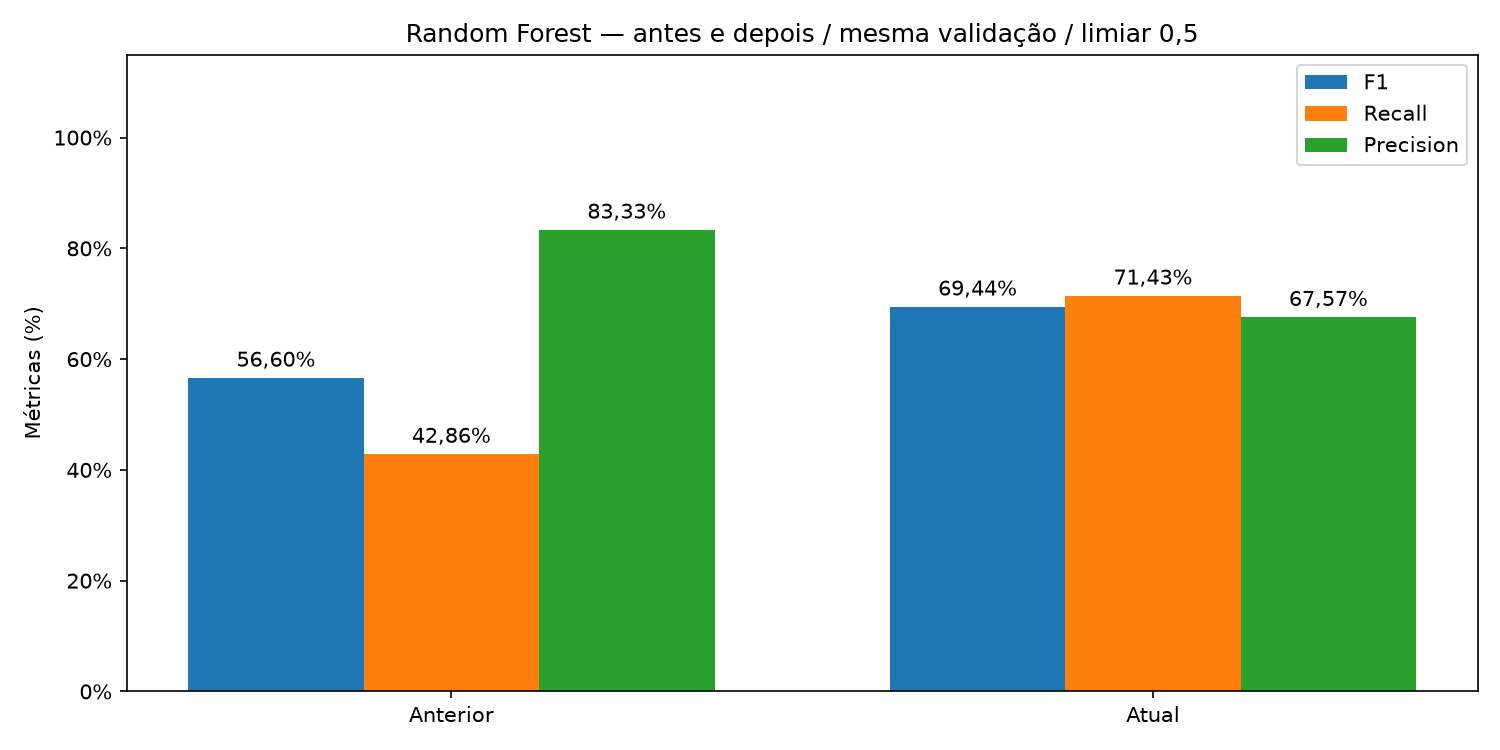

AUPRC: 0,7180 → 0,7479; AP: 0,7205 → 0,7499; F1: 56,60% → 69,44%. Não houve ajuste de limiar nesta comparação.

In [12]:
comparison = report.table('previous_comparison')
display(readable_table(comparison[['version', 'threshold', 'auprc', 'ap', 'f1', 'recall', 'precision', 'fp', 'fn']]))
from IPython.display import Image
display(Image(filename=str(report.figures / 'previous_comparison.png')))
before, after = comparison.iloc[0], comparison.iloc[1]
display(translated_markdown(f'AUPRC: {before.auprc:.4f} → {after.auprc:.4f}; ' f'AP: {before.ap:.4f} → {after.ap:.4f}; ' f'F1: {before.f1:.2%} → {after.f1:.2%}. ' 'Não houve ajuste de limiar nesta comparação.'))

## 13. Auditoria do SMOTENC

Contagens do sampler escolhido por treino e refit; auditoria dos folds sem novo ajuste de classificador. Validação não é reamostrada.

In [13]:
display(readable_table(report.table('sampling_counts')))

,Origem,Não falhas antes do sampler,Falhas antes do sampler,Não falhas após sampler,Falhas após sampler,Falhas sintéticas criadas
0,CV_FIT_1,1.555,45,1.555,388,343
1,CV_FIT_2,3.123,77,3.123,780,703
2,CV_FIT_3,4.579,221,4.579,1.144,923
3,REFIT,6.135,265,6.135,1.533,1.268


## 14. Estratégias de balanceamento — decisão na CV

Melhor configuração de cada braço segundo AP, com dispersão entre folds.
Somente candidatos com SMOTENC são elegíveis para refit, conforme o requisito.
Os controles podem ter score maior; isso será mostrado, sem ocultar ou chamá-los de escolhidos.
As tabelas desta seção são de CV de seleção, não do bloco de validação.
O verde destaca a escolha; cinza identifica controles. Não há confirmação estatística independente.

,strategy,Elegível para refit?,Selecionada?,Índice do candidato,AP (score) — média — validação CV,AP (score) — desvio — validação CV,F1 (%) — média — validação CV,Recall (%) — média — validação CV,Precision (%) — média — validação CV,Parâmetros
0,Sem balanceamento (controle),Não,Não,4,"0,5069","0,0983","40,85%","41,93%","66,82%","{""model__class_weight"": null, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
3,Só pesos (controle),Não,Não,8,"0,4925","0,1137","39,71%","44,71%","55,67%","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": null, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 1, ""sampler"": ""passthrough""}"
1,SMOTENC,Sim,Sim,30,"0,4632","0,0637","39,50%","55,56%","41,61%","{""model__class_weight"": null, ""model__max_depth"": null, ""model__max_features"": 1.0, ""model__min_samples_leaf"": 4, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"
2,SMOTENC + pesos,Sim,Não,50,"0,4336","0,0378","36,29%","54,00%","38,67%","{""model__class_weight"": {""0"": 1, ""1"": 3}, ""model__max_depth"": 10, ""model__max_features"": ""sqrt"", ""model__min_samples_leaf"": 4, ""sampler"": ""SMOTENC"", ""sampler__sampling_strategy"": 0.25}"


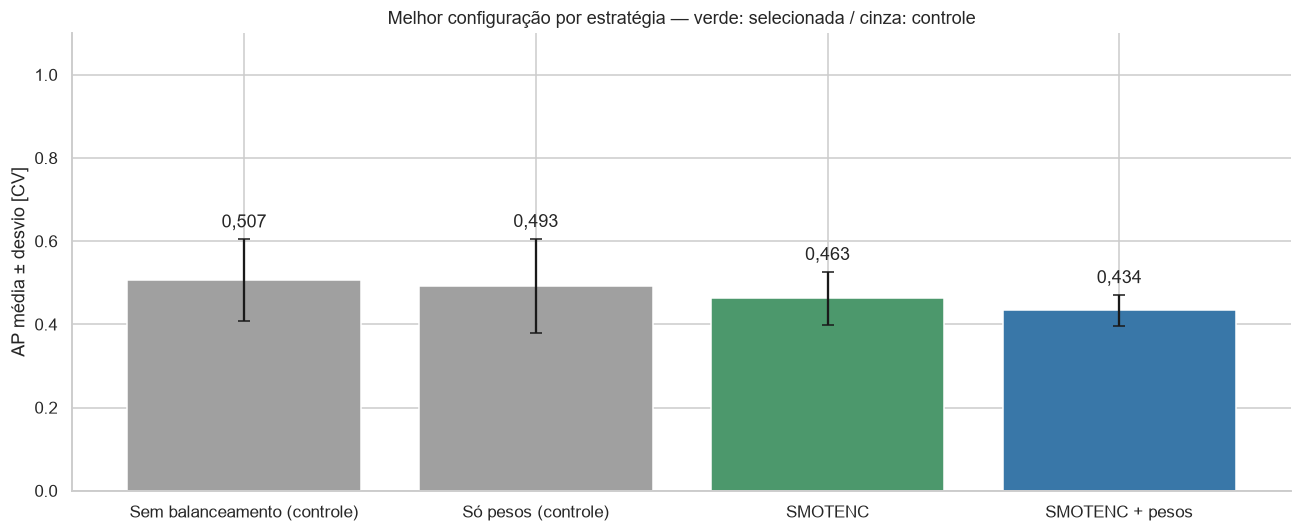

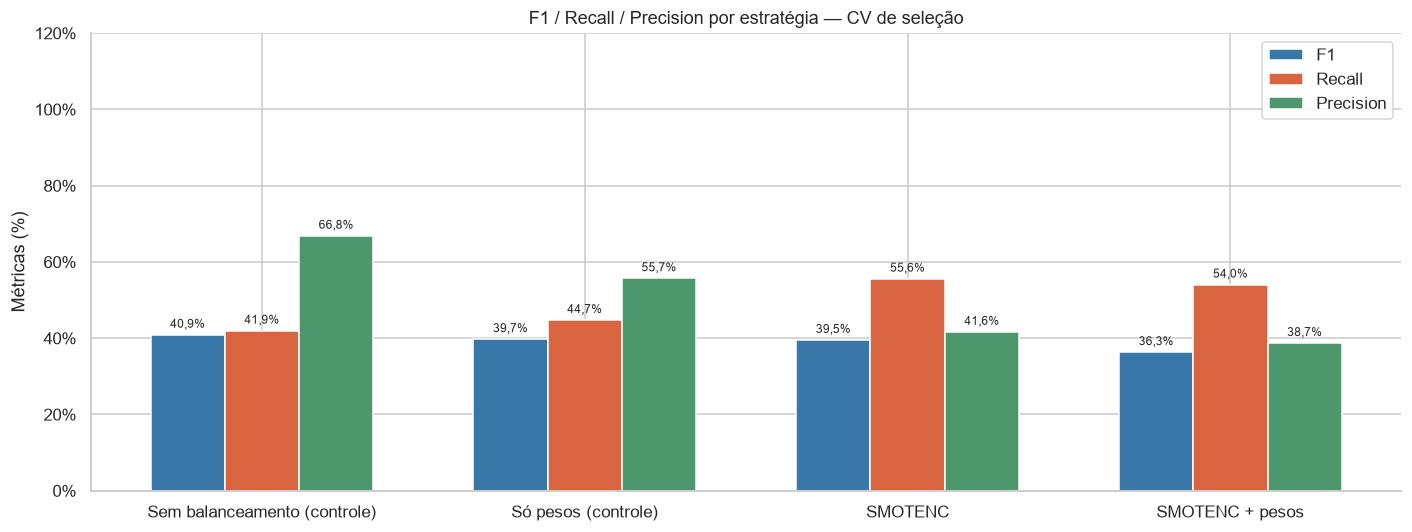

Melhor índice irrestrito: 4; selecionado com SMOTENC: 30. A escolha usa CV, nunca as métricas do bloco de validação.

In [14]:
strategies = report.table('strategy_cv_summary')
metric = report.selection_metric
columns = ['strategy', 'eligible_for_refit', 'selected', 'candidate_index', f'mean_test_{metric}', f'std_test_{metric}', 'mean_test_f1', 'mean_test_recall', 'mean_test_precision', 'params']
display(readable_table(strategies.sort_values(f'mean_test_{metric}', ascending=False)[columns]))
report.strategy_figures()
overall = int(manifest['global_best_candidate_index'])
selected = int(manifest['best_candidate_index'])
display(translated_markdown(f'Melhor índice irrestrito: {overall}; selecionado com SMOTENC: {selected}. ' 'A escolha usa CV, nunca as métricas do bloco de validação.'))